In [1]:
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import os
from venv import create
import pylops
import scipy.special as spe
from trips.test_problems.Deblurring2D import *
from trips.utilities.operators import *
from trips.utilities.helpers import *
from trips.solvers.GKS import *
from trips.solvers.MMGKS import *
from trips.solvers.Tikhonov import *
from trips.solvers.tSVD import *
from trips.solvers.Hybrid_GMRES import *
from trips.solvers.Hybrid_LSQR import *
from scipy.linalg import qr

from gksias import GKSIAS

import jlinops

In [27]:
# Create an object of class Deblurring()
Deblur = Deblurring2D(CommitCrime = False)

#img = jlinops.satellite()
img = jlinops.graecolatinsquare(which=3)
img_shape = img.shape
nx, ny = img.shape
A = Deblur.forward_Op((9,9), (3,3), nx, ny)
btrue = A @ img.flatten()
delta = 0.1
b = btrue + delta*np.random.normal(size=btrue.shape)

# b_vec = b.reshape((-1,1))

(<Axes: title={'center': 'b'}>,
 Text(0.5, 1.0, 'b'),
 (0.0, 1.0, 0.0, 1.0),
 <matplotlib.image.AxesImage at 0x15621d850>)

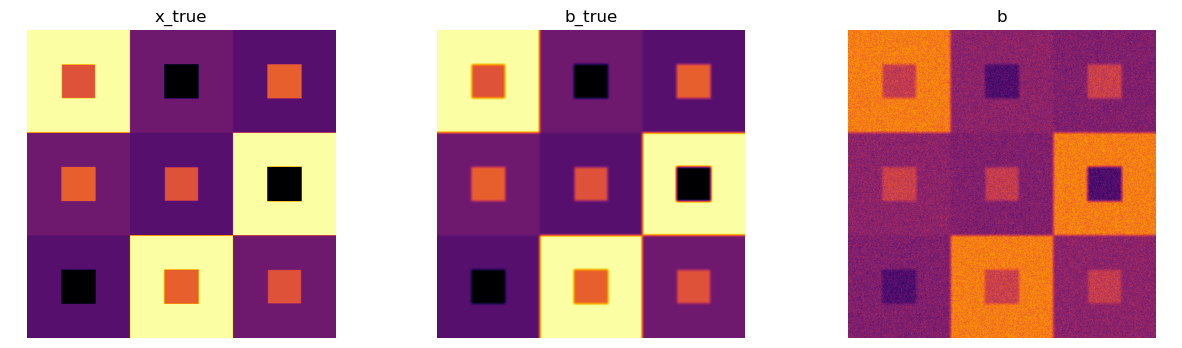

In [28]:
# Display the true desired vs the naive computed solution and vs the approximate regularized computed solution 
plt.figure(figsize=(15,4))
plt.set_cmap('inferno')
plt.axis('off')
plt.subplot(1,3,1), plt.title('x_true'), plt.axis('off'), plt.imshow(img)
plt.subplot(1,3,2), plt.title('b_true'), plt.axis('off'), plt.imshow(btrue.reshape((nx,ny)))
plt.subplot(1,3,3), plt.title('b'), plt.axis('off'), plt.imshow(b.reshape((nx,ny)))


In [29]:
# # Compute a solution by GKS
# # Define a derivative operator as a regularization operator
# L = first_derivative_operator_2d(nx, ny)
# data_vec = b.reshape((-1,1))
# # Use GKS to compute an approximate solution
# (x_gks, info_gks) = GKS(A, data_vec, L, projection_dim=3, n_iter = 100, regparam = 'gcv', x_true = img, delta = delta)

In [30]:
L = first_derivative_operator_2d(nx, ny)
data_vec = b
Atilde = (1.0/delta)*A
btilde = (1.0/delta)*b
(x_mmgks_R, info_mmgks_R) = GKSIAS(Atilde, btilde, L, hyperpr_r=-1.0, hyperpr_beta=1.0, projection_dim=5, n_iter=200, regparam = 'gcv', x_true = img.flatten(), keep_x=True )

running MMGKS...: 100%|██████████| 200/200 [8:32:32<00:00, 153.76s/it]   


In [36]:
result = x_mmgks_R.reshape(img_shape)

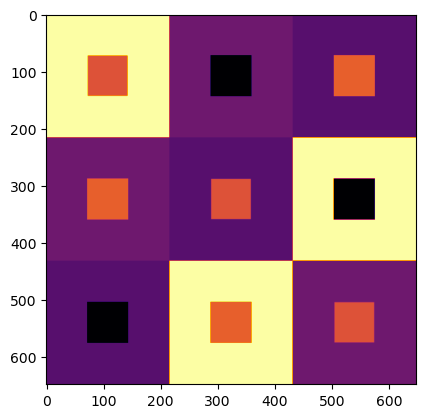

In [37]:
plt.imshow(img)
plt.show()

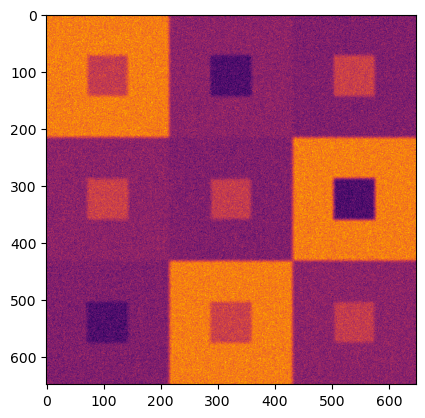

In [38]:
plt.imshow(b.reshape(img_shape))
plt.show()

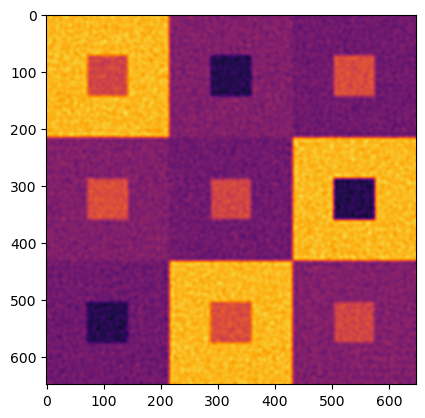

In [40]:
plt.imshow(result)
plt.show()

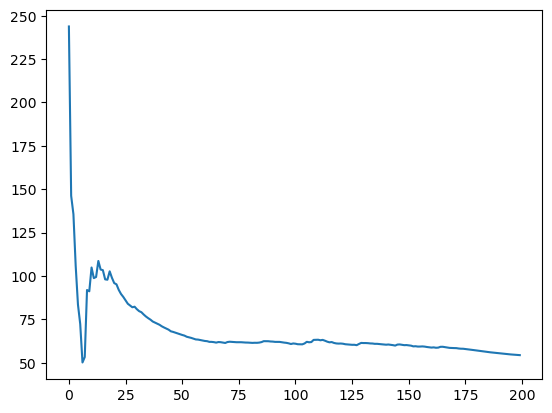

In [41]:
plt.plot(info_mmgks_R["regParam_history"])
plt.show()

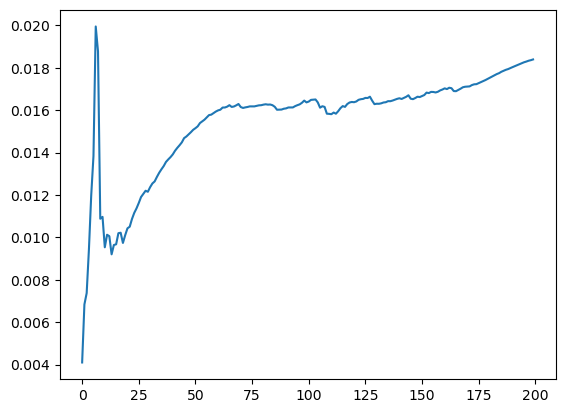

In [43]:
plt.plot(1.0/np.asarray(info_mmgks_R["regParam_history"]) )
plt.show()